# Broad-Spectrum Antibiotic Prescribing and Antimicrobial Resistance


In [ ]:
from pathlib import Path
import json
import shutil
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

# The notebook is stored at the repository root.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "scripts" / "demo.yaml").exists():
    raise RuntimeError("Run this notebook from the repository root.")

SCRIPT_DIR = PROJECT_ROOT / "scripts"
if str(SCRIPT_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPT_DIR))

from england_amr.config import load_config
from england_amr.synthetic import generate_demo_data
from england_amr.validation import run_validation
from england_amr.preprocess import run_preprocessing
from england_amr.analysis import run_analysis
from england_amr.modeling import run_training
from england_amr.scenario import run_scenario
from england_amr.visualization import (
    plot_national_trends,
    plot_trajectory_scatter,
    plot_class_counts,
    plot_lag_coefficients,
    plot_feature_importance,
    plot_calibration,
    plot_scenario,
)

CONFIG_PATH = SCRIPT_DIR / "demo.yaml"
cfg = load_config(CONFIG_PATH)

# Remove generated intermediates and outputs so every run starts clean.
for rel in ["data/interim", "data/processed", "output/tables", "output/model", "figures"]:
    path = PROJECT_ROOT / rel
    if path.exists():
        shutil.rmtree(path)
cfg.ensure_directories()

print(f"Project: {PROJECT_ROOT.name}")
print(f"Analysis period: {cfg.get('project.start_date')} to {cfg.get('project.end_date')}")
print(f"Primary resistance outcome: {', '.join(cfg.get('analysis.primary_antibiotics'))}")

Project: antibiotic-amr-project
Analysis period: 2021-04-01 to 2026-04-30
Primary resistance outcome: co-amoxiclav


##  Simulation analysis

The simulation creates monthly prescribing, resistance surveillance, testing volume, and area-level covariates for 40 regions. 

In [ ]:
paths = generate_demo_data(cfg, n_areas=40)
prescribing_raw = pd.read_csv(paths["prescribing"])
resistance_raw = pd.read_csv(paths["resistance"])
covariates_raw = pd.read_csv(paths["covariates"])

coverage = pd.DataFrame({
    "dataset": ["Prescribing", "Resistance surveillance", "Regional covariates"],
    "rows": [len(prescribing_raw), len(resistance_raw), len(covariates_raw)],
    "areas": [prescribing_raw["row_id"].nunique(), resistance_raw["requested_geography"].nunique(), covariates_raw["area_code"].nunique()],
})
display(coverage)

,dataset,rows,areas
0,Prescribing,2440,40
1,Resistance surveillance,7320,40
2,Regional covariates,240,40


In [ ]:
validation = run_validation(cfg)
validation_summary = (
    validation.groupby(["dataset", "severity"], as_index=False)
    .agg(checks=("check", "count"), passed=("passed", "sum"))
)
display(validation_summary)

assert validation["passed"].all(), "At least one data validation check failed."
print(f"All {len(validation)} configured validation checks passed.")

,dataset,severity,checks,passed
0,covariates,error,4,4
1,prescribing,error,4,4
2,prescribing,warning,1,1
3,resistance,error,5,5


All 14 configured validation checks passed.


## Panel construction and overall trends

Monthly prescribing and resistance records are standardized and aligned to non-overlapping quarterly anchors. Testing-volume thresholds are applied to the resistance outcome, and annual demographic and disease-burden variables are joined by area and year.

In [ ]:
run_preprocessing(cfg)
panel_path = cfg.path("paths.processed_dir") / "area_quarter_panel.csv"
panel = pd.read_csv(panel_path, parse_dates=["quarter"])

panel_summary = pd.DataFrame({
    "measure": ["Panel rows", "Areas", "Quarter count", "Start", "End"],
    "value": [
        len(panel),
        panel["area_code"].nunique(),
        panel["quarter"].nunique(),
        panel["quarter"].min().date(),
        panel["quarter"].max().date(),
    ],
})
display(panel_summary)
display(panel.head())

,measure,value
0,Panel rows,840
1,Areas,40
2,Quarter count,21
3,Start,2021-04-01
4,End,2026-04-01


,area_code,quarter,broad_spectrum_items_per_1000,broad_spectrum_items,total_list_size,antibiotic,resistance_percent,n_tested,percent_tested,area_name,year,age65_share,age80_share,imd_score,diabetes_prevalence,ckd_prevalence,copd_prevalence,cancer_prevalence
0,SICBL001,2021-04-01,3.558236,928,86972.0,co-amoxiclav,17.006716,93.0,89.107337,Demo Sub-ICB 01,2021,0.16425,0.038763,34.089241,0.076424,0.048546,0.027842,0.031268
1,SICBL001,2021-07-01,3.686413,962,86972.0,co-amoxiclav,16.625591,104.0,80.783808,Demo Sub-ICB 01,2021,0.16425,0.038763,34.089241,0.076424,0.048546,0.027842,0.031268
2,SICBL001,2021-10-01,4.103598,1070,86972.0,co-amoxiclav,16.589765,99.0,76.084793,Demo Sub-ICB 01,2021,0.16425,0.038763,34.089241,0.076424,0.048546,0.027842,0.031268
3,SICBL001,2022-01-01,4.009978,1046,86972.0,co-amoxiclav,17.032082,99.0,70.707215,Demo Sub-ICB 01,2022,0.16475,0.039013,34.089241,0.076924,0.048796,0.027842,0.031518
4,SICBL001,2022-04-01,3.545523,926,86972.0,co-amoxiclav,16.733965,113.0,84.628275,Demo Sub-ICB 01,2022,0.16475,0.039013,34.089241,0.076924,0.048796,0.027842,0.031518


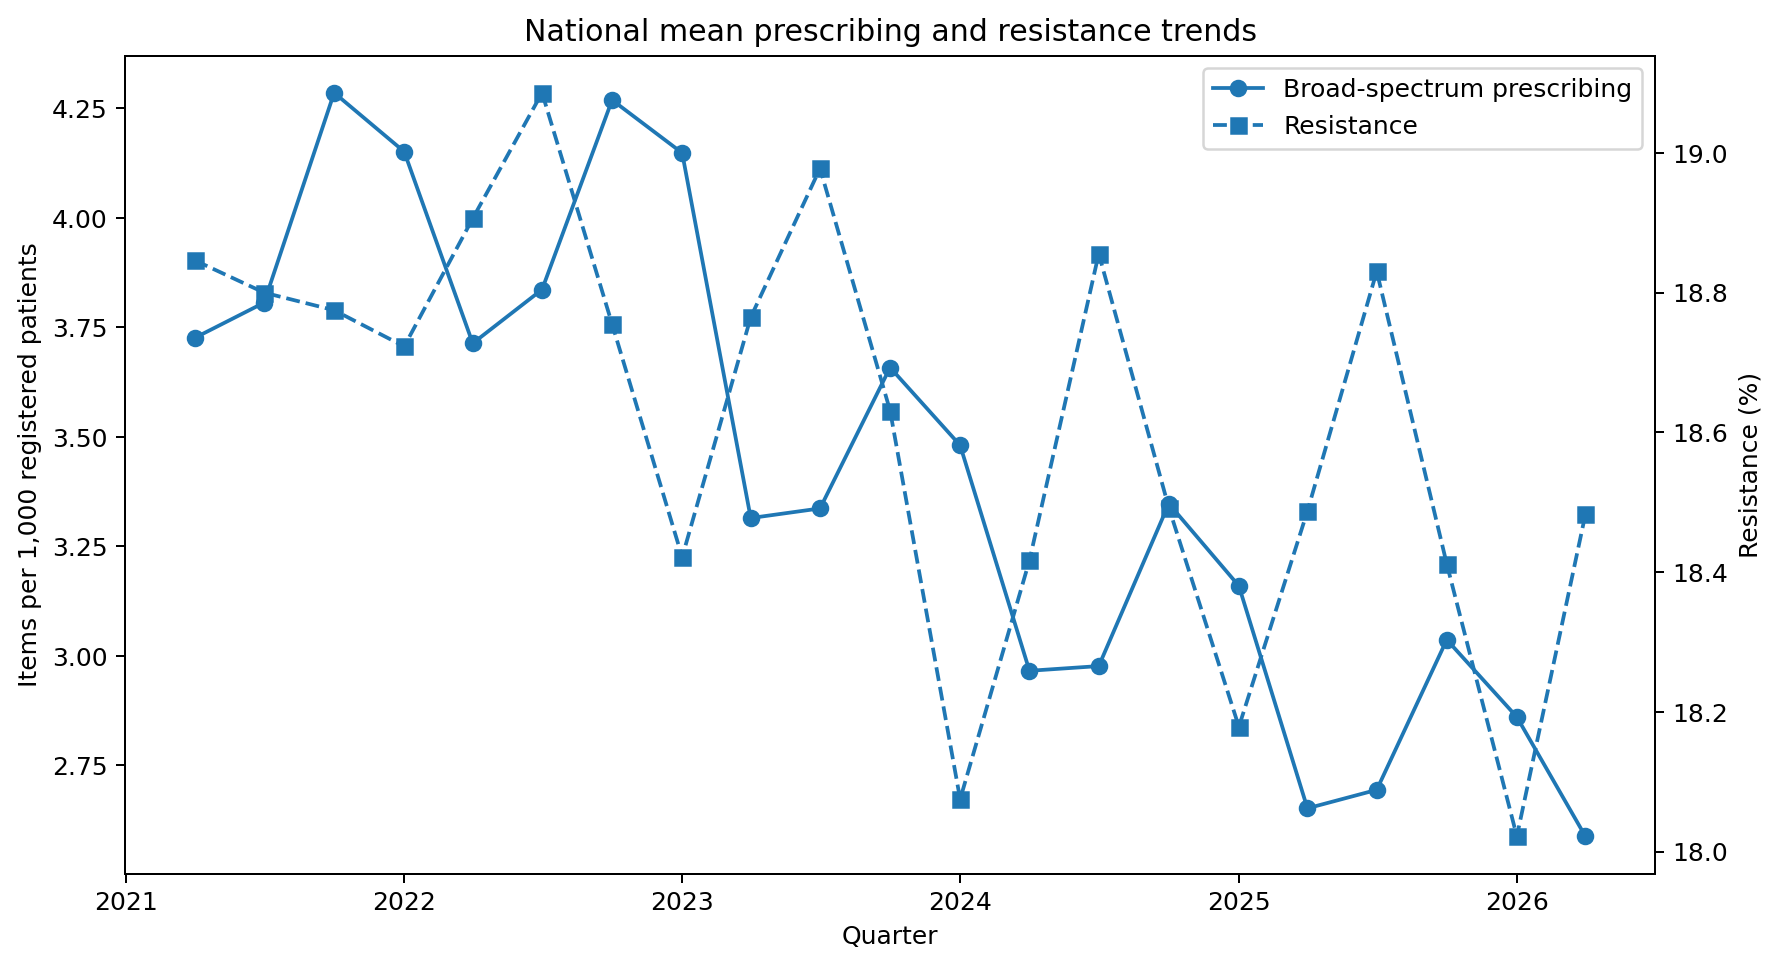

In [ ]:
figure_dir = cfg.path("paths.figure_dir")
figure_dir.mkdir(parents=True, exist_ok=True)
national_path = figure_dir / "national_trends.png"
plot_national_trends(panel, national_path)
display(Image(filename=str(national_path)))

## Regional heterogeneity and response patterns


In [ ]:
analysis_outputs = run_analysis(cfg)
table_dir = cfg.path("paths.table_dir")

classes = pd.read_csv(table_dir / "four_trajectory_classes.csv")
clusters = pd.read_csv(table_dir / "dtw_cluster_assignments.csv")
cluster_metrics = json.loads((table_dir / "clustering_metrics.json").read_text())

class_counts = classes["trajectory_class"].value_counts().rename_axis("trajectory_class").reset_index(name="areas")
display(class_counts)
display(pd.DataFrame([cluster_metrics]))

,trajectory_class,areas
0,prescribing_down_resistance_not_down,10
1,prescribing_not_down_resistance_down,10
2,neither_improved,10
3,prescribing_down_resistance_down,10


,silhouette_precomputed,adjusted_rand_vs_synthetic_truth
0,0.489505,1.0


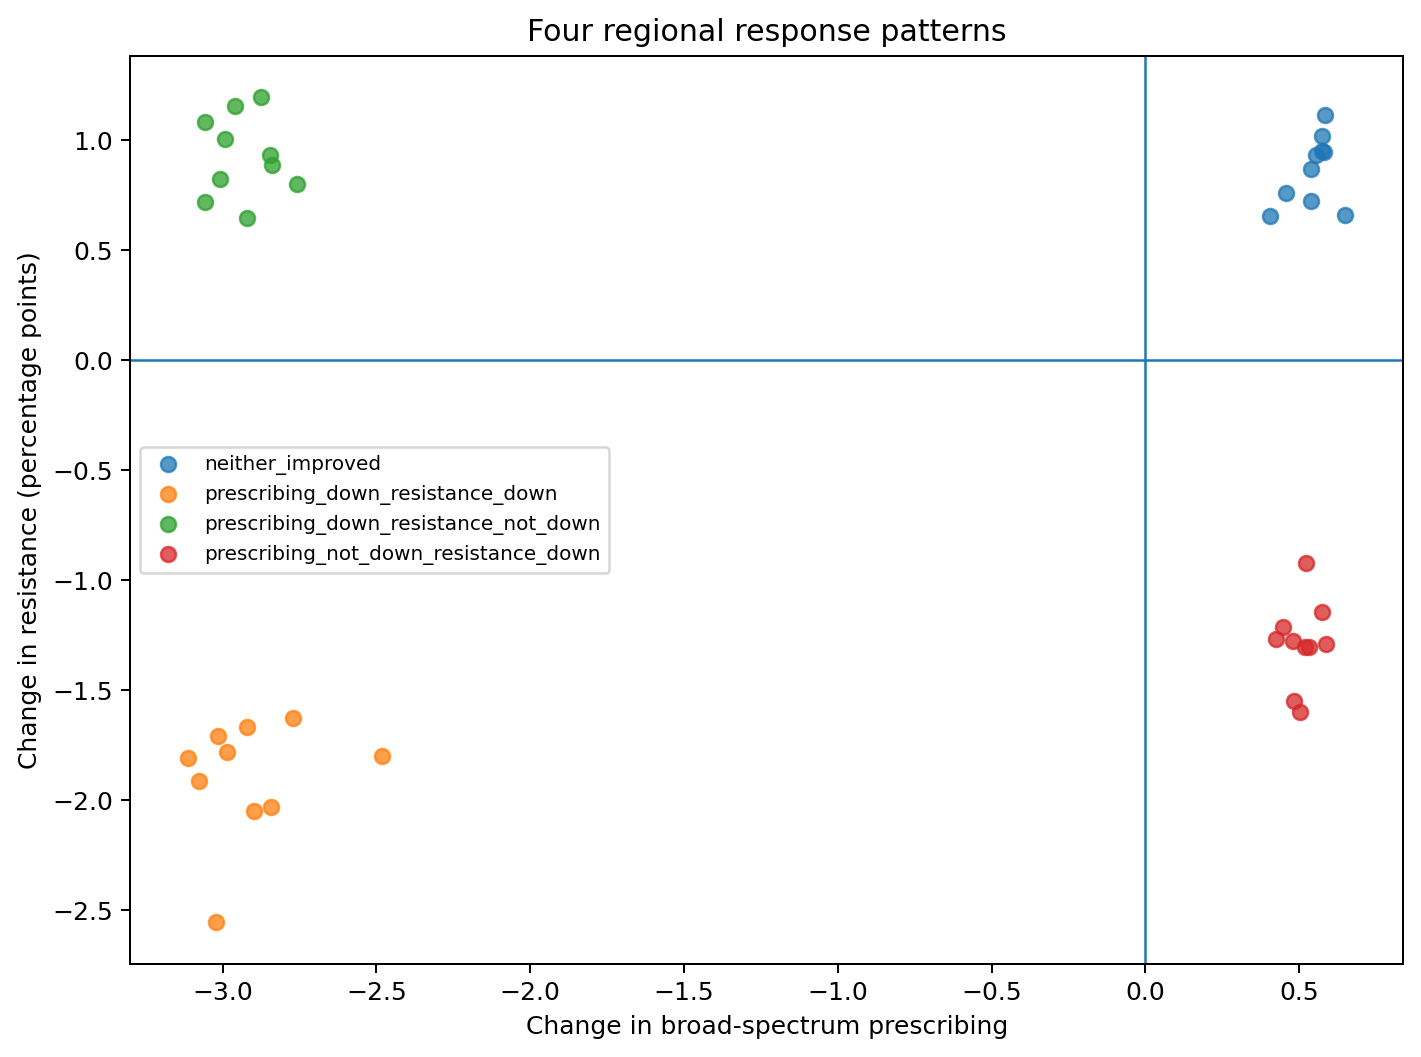

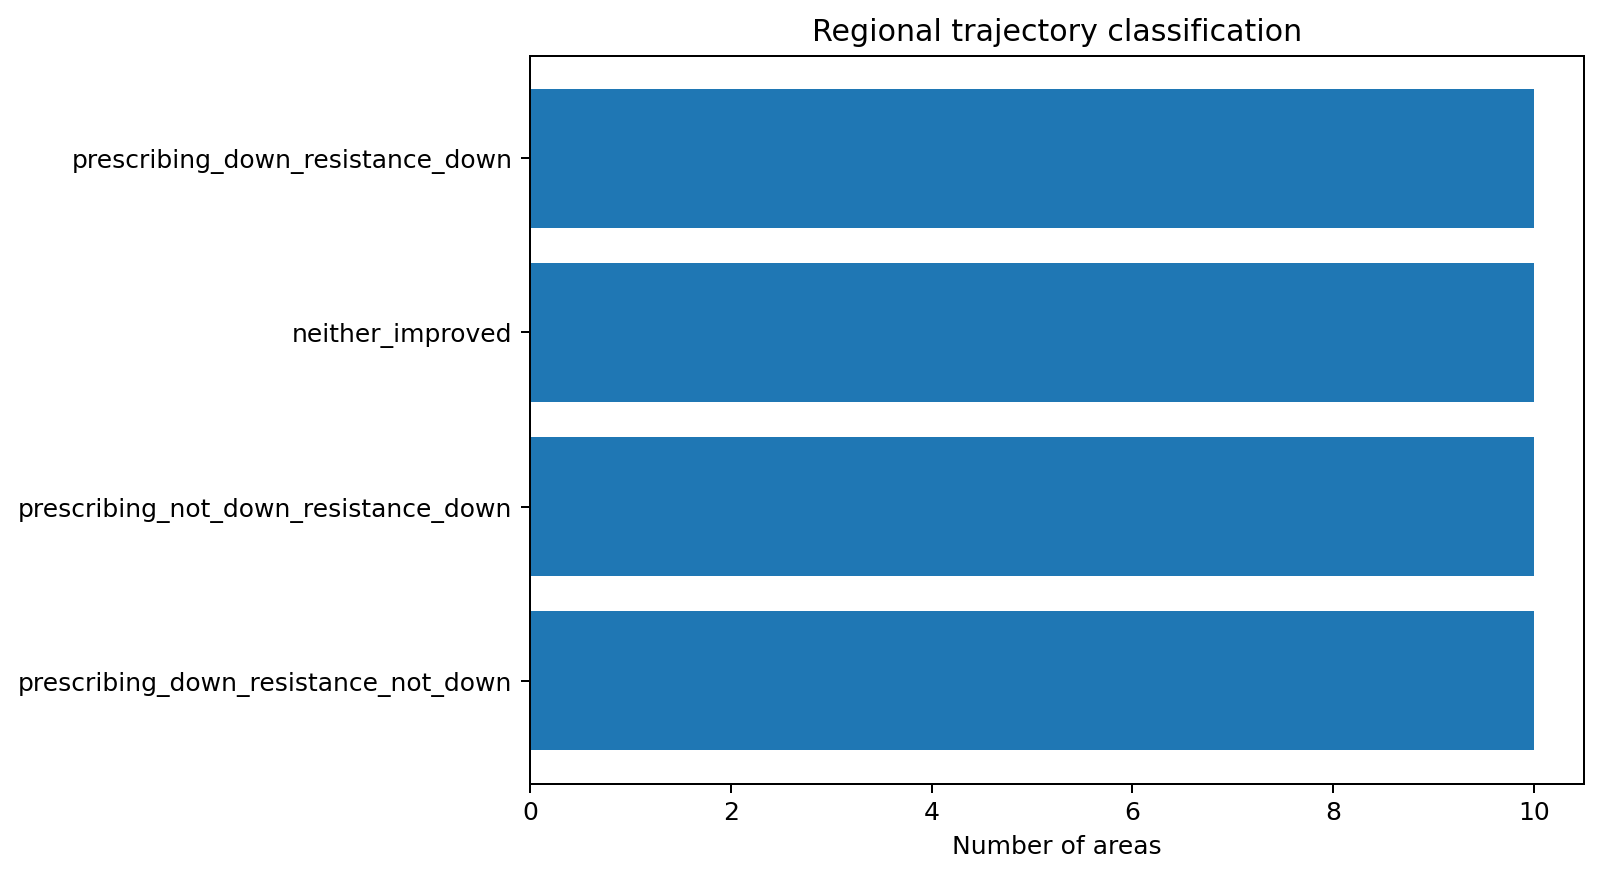

In [ ]:
trajectory_path = figure_dir / "trajectory_scatter.png"
class_count_path = figure_dir / "trajectory_class_counts.png"
plot_trajectory_scatter(classes, trajectory_path)
plot_class_counts(classes, class_count_path)
display(Image(filename=str(trajectory_path)))
display(Image(filename=str(class_count_path)))

## Temporal lag analysis


In [ ]:
lags = pd.read_csv(table_dir / "distributed_lag_fixed_effects.csv")
its = pd.read_csv(table_dir / "interrupted_time_series.csv")

display(lags[["lag_quarters", "estimate_per_1sd_prescribing", "ci_low", "ci_high", "p_value", "n_observations"]])

display(
    its[its["term"].isin(["time", "post", "time_after"])][
        ["term", "estimate", "ci_low", "ci_high", "p_value"]
    ].reset_index(drop=True)
)

,lag_quarters,estimate_per_1sd_prescribing,ci_low,ci_high,p_value,n_observations
0,1,-0.121595,-0.353764,0.110574,0.304654,680
1,2,0.050186,-0.320330,0.420701,0.790645,680
2,3,0.685516,0.362728,1.008305,0.000031,680
3,4,-0.470896,-0.856955,-0.084837,0.016818,680


,term,estimate,ci_low,ci_high,p_value
0,time,0.000262,-0.000726,0.001249,6.034676e-01
1,post,-0.403289,-0.431641,-0.374937,4.796935e-171
2,time_after,-0.025154,-0.026423,-0.023886,0.000000e+00


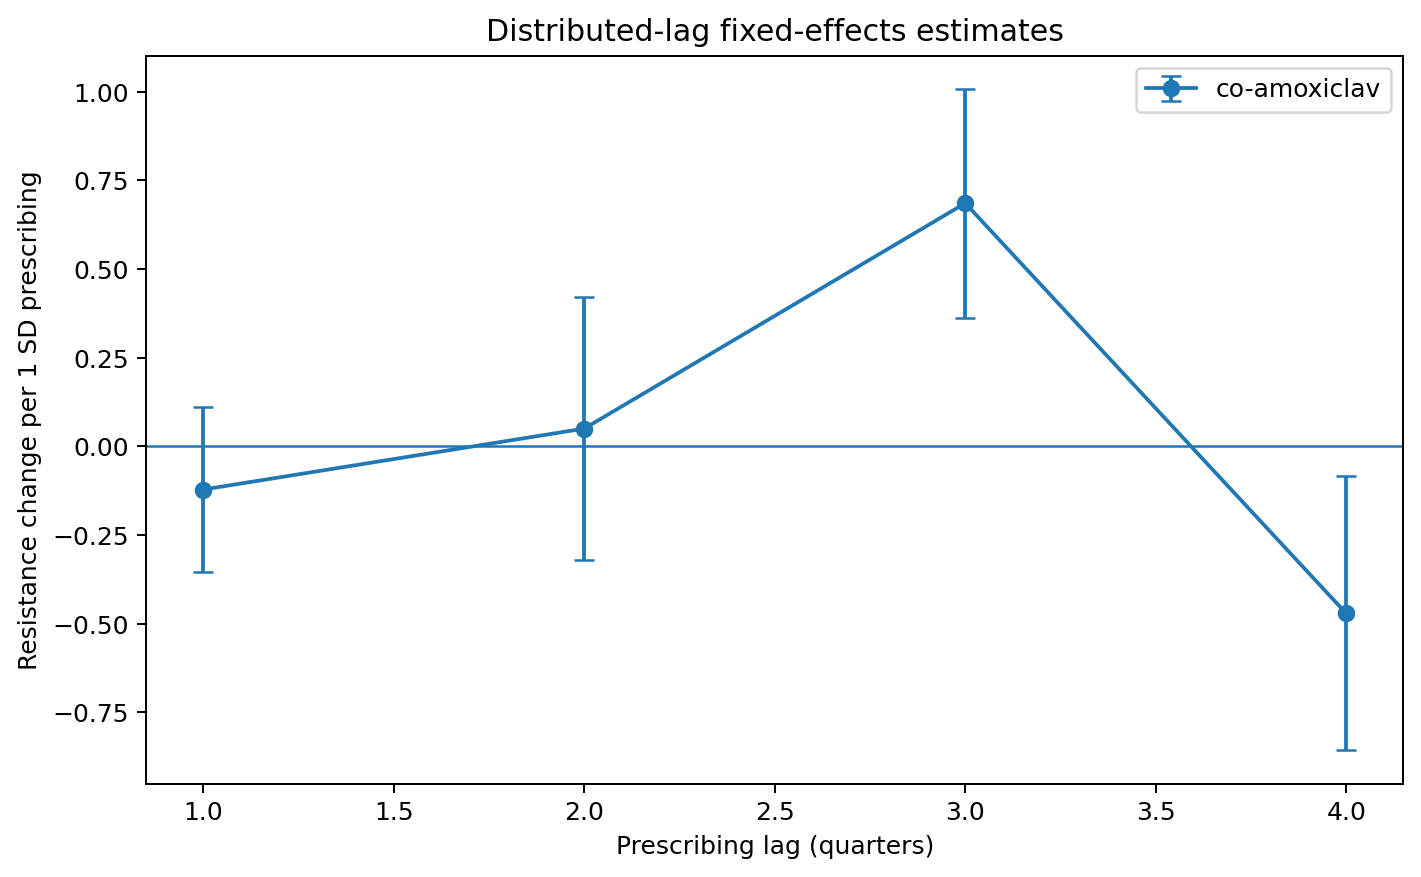

In [ ]:
lag_path = figure_dir / "distributed_lag_coefficients.png"
plot_lag_coefficients(lags, lag_path)
display(Image(filename=str(lag_path)))

## Predicting later resistance improvement

The predictive task is defined at the area-quarter level. The target indicates whether resistance falls by at least 0.5 percentage points four quarters later. 

In [ ]:
training_outputs = run_training(cfg)
rolling = pd.read_csv(table_dir / "rolling_origin_metrics.csv")
metrics = json.loads((table_dir / "final_holdout_metrics.json").read_text())
importance = pd.read_csv(table_dir / "model_feature_importance.csv")
shap_importance = pd.read_csv(table_dir / "shap_importance.csv")
holdout = pd.read_csv(table_dir / "final_holdout_predictions.csv")

rolling_display = rolling[[
    "fold", "train_end", "test_end", "test_positive_rate",
    "balanced_accuracy", "roc_auc", "average_precision"
]].round(3)
display(rolling_display)

display(pd.DataFrame({
    "metric": ["Balanced accuracy", "ROC-AUC", "Average precision", "F1", "Precision", "Recall", "Brier score"],
    "value": [metrics["balanced_accuracy"], metrics["roc_auc"], metrics["average_precision"], metrics["f1"], metrics["precision"], metrics["recall"], metrics["brier"]],
}).round(3))

,fold,train_end,test_end,test_positive_rate,balanced_accuracy,roc_auc,average_precision
0,1,2023-01-01,2023-07-01,0.442,0.875,0.947,0.889
1,2,2023-07-01,2024-01-01,0.233,0.573,0.548,0.270
2,3,2024-01-01,2024-07-01,0.070,0.621,0.583,0.109
3,4,2024-07-01,2025-01-01,0.200,0.472,0.731,0.316


,metric,value
0,Balanced accuracy,0.722
1,ROC-AUC,0.710
2,Average precision,0.261
3,F1,0.429
4,Precision,0.273
5,Recall,1.000
6,Brier score,0.147


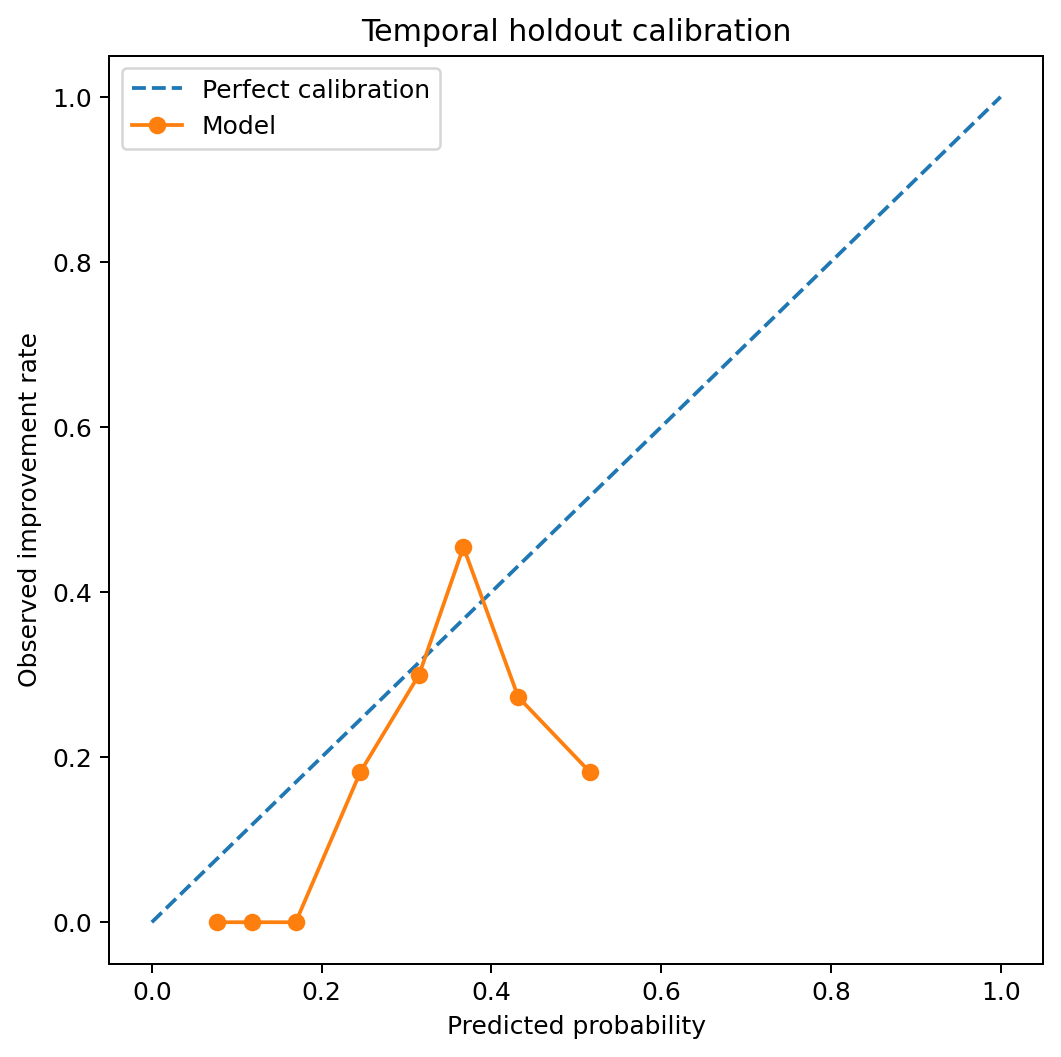

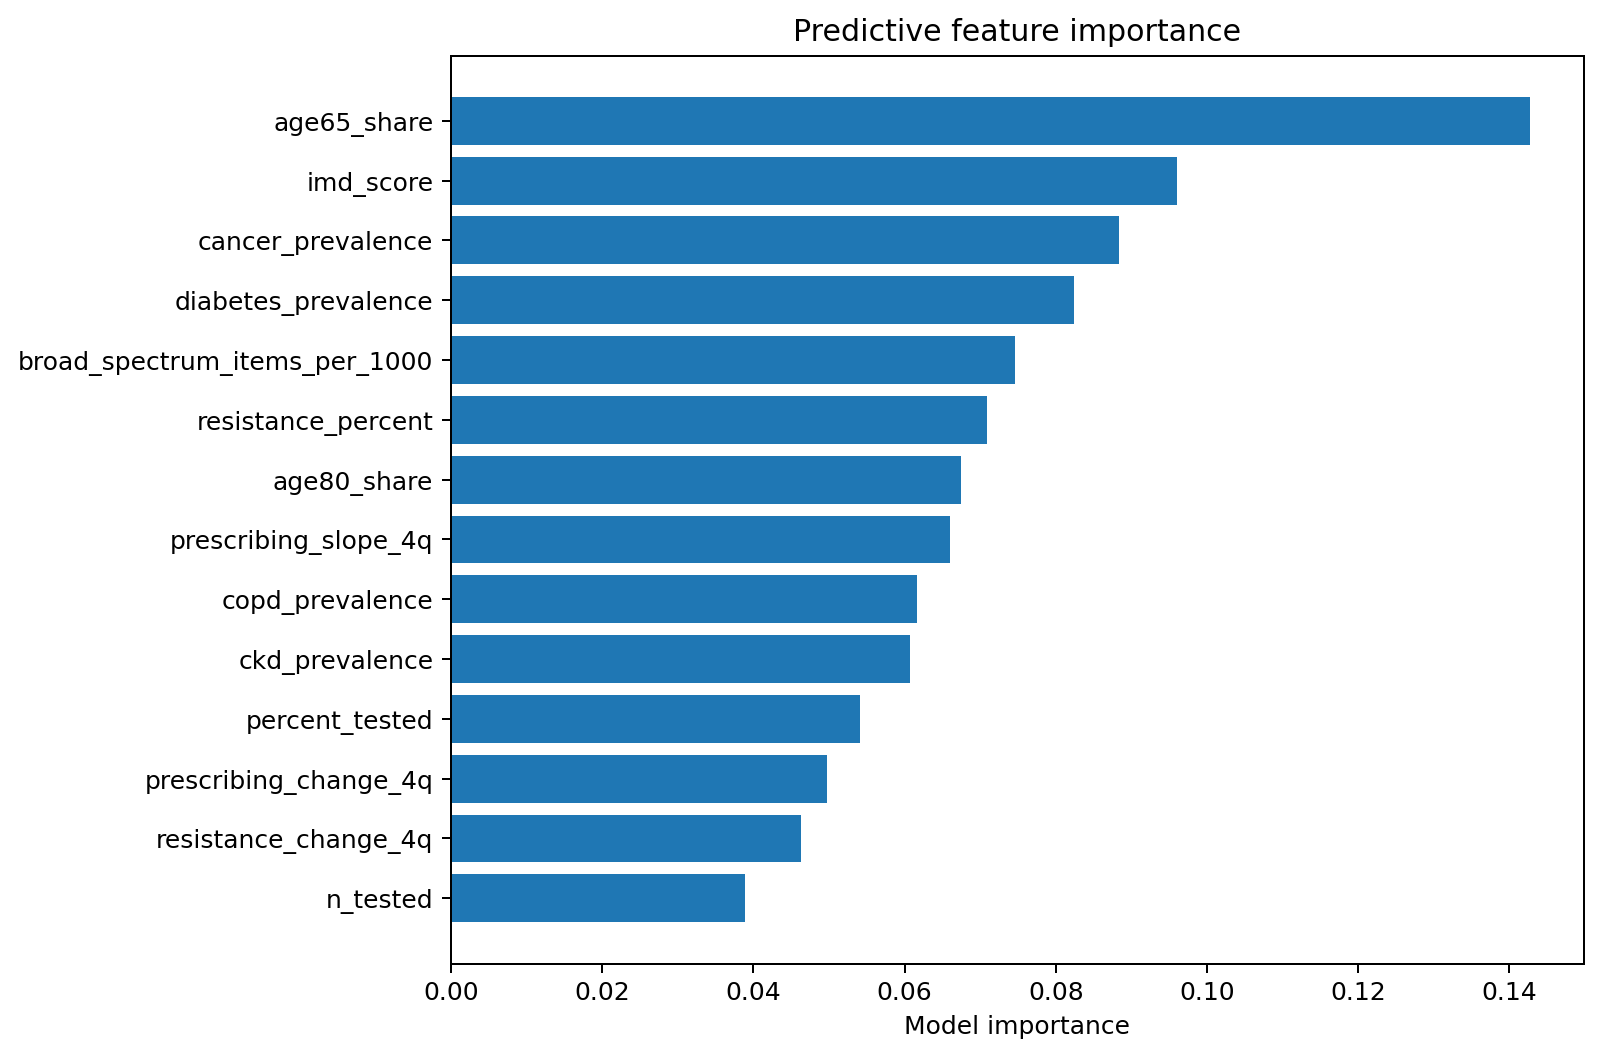

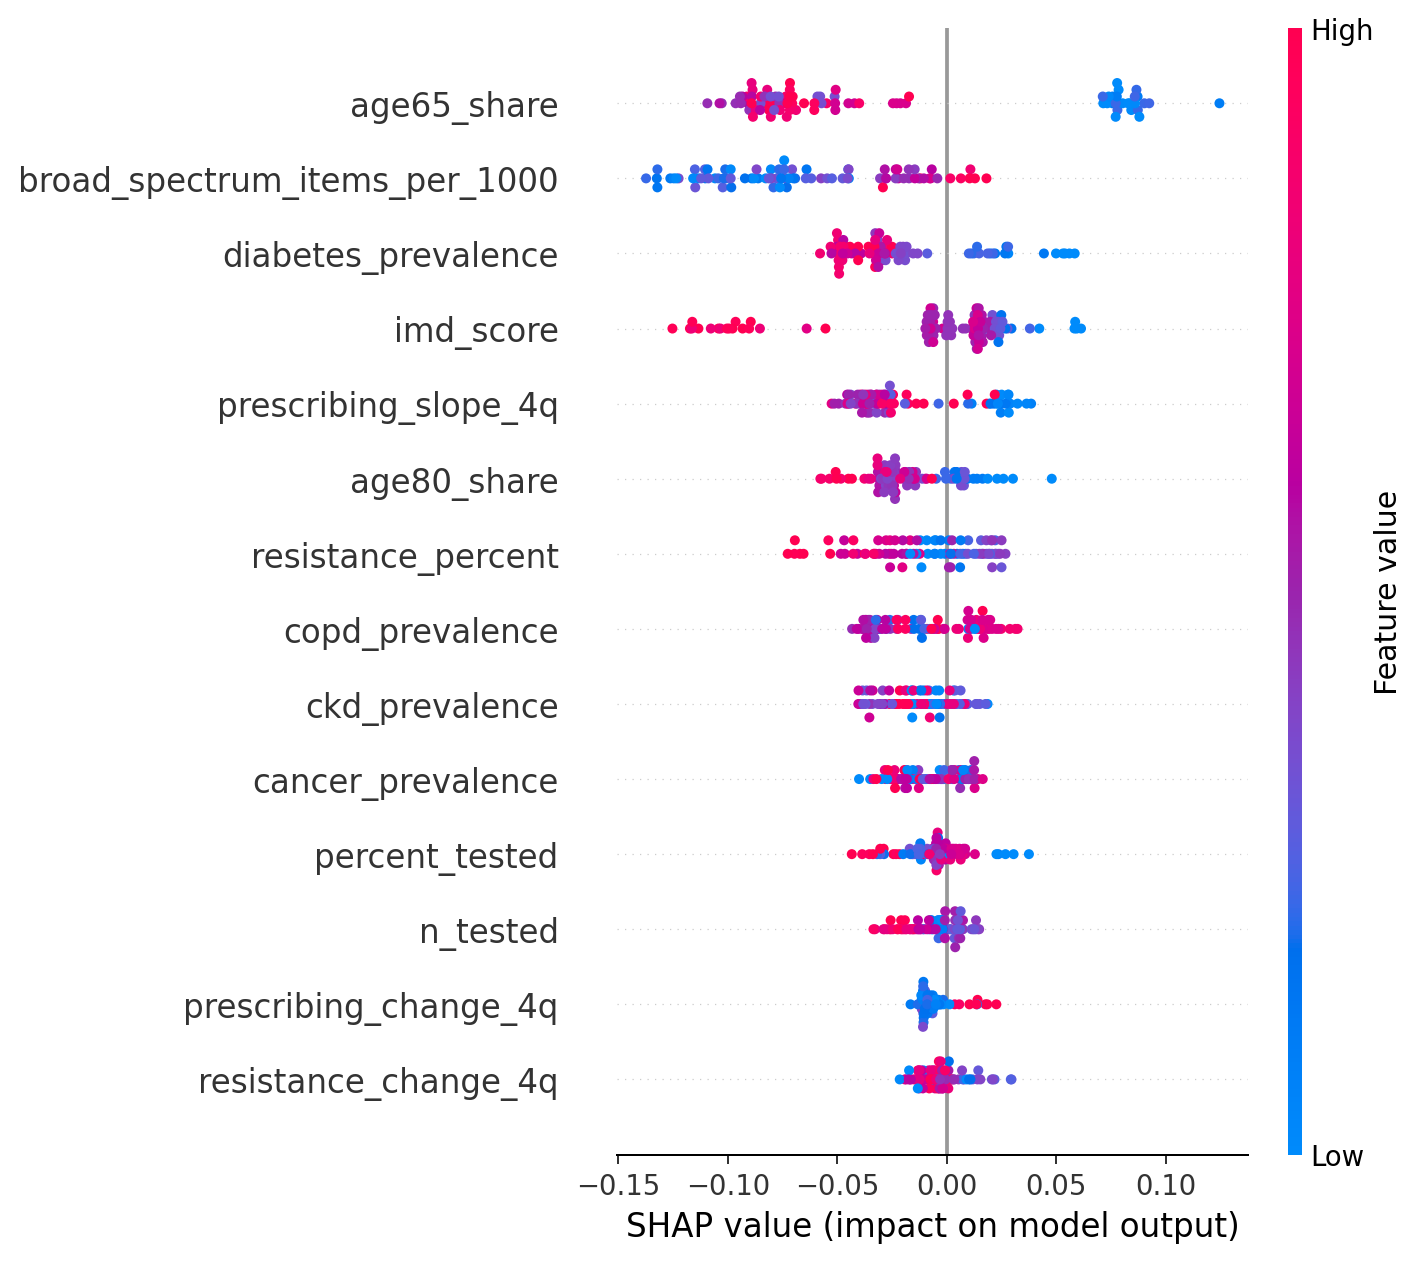

,feature,mean_abs_shap
0,age65_share,0.0746
1,broad_spectrum_items_per_1000,0.0665
2,diabetes_prevalence,0.0338
3,imd_score,0.0333
4,prescribing_slope_4q,0.0301
5,age80_share,0.0228
6,resistance_percent,0.0221
7,copd_prevalence,0.0214
8,ckd_prevalence,0.0168
9,cancer_prevalence,0.0135


In [ ]:
calibration_path = figure_dir / "calibration_curve.png"
importance_path = figure_dir / "feature_importance.png"
plot_calibration(holdout, calibration_path)
plot_feature_importance(importance, importance_path)

display(Image(filename=str(calibration_path)))
display(Image(filename=str(importance_path)))

shap_path = figure_dir / "shap_summary.png"
if shap_path.exists():
    display(Image(filename=str(shap_path)))

display(shap_importance.head(10).round(4))

## Peer-median prescribing scenario

regions are grouped by demographic, socioeconomic, disease-burden, and resistance characteristics. 

,area_name,broad_spectrum_items_per_1000,peer_target_prescribing,observed_probability,scenario_probability,predicted_probability_change
650,Demo Sub-ICB 31,4.291,2.758,0.176,0.207,0.031
209,Demo Sub-ICB 10,4.895,2.758,0.156,0.187,0.031
335,Demo Sub-ICB 16,5.291,2.758,0.125,0.127,0.002
230,Demo Sub-ICB 11,0.500,0.500,0.407,0.407,0.000
377,Demo Sub-ICB 18,1.342,2.758,0.163,0.163,0.000
398,Demo Sub-ICB 19,0.500,2.568,0.189,0.189,0.000
608,Demo Sub-ICB 29,0.500,2.568,0.116,0.116,0.000
818,Demo Sub-ICB 39,0.500,4.119,0.094,0.094,0.000
503,Demo Sub-ICB 24,0.500,3.838,0.344,0.344,0.000
839,Demo Sub-ICB 40,0.500,0.500,0.345,0.345,0.000


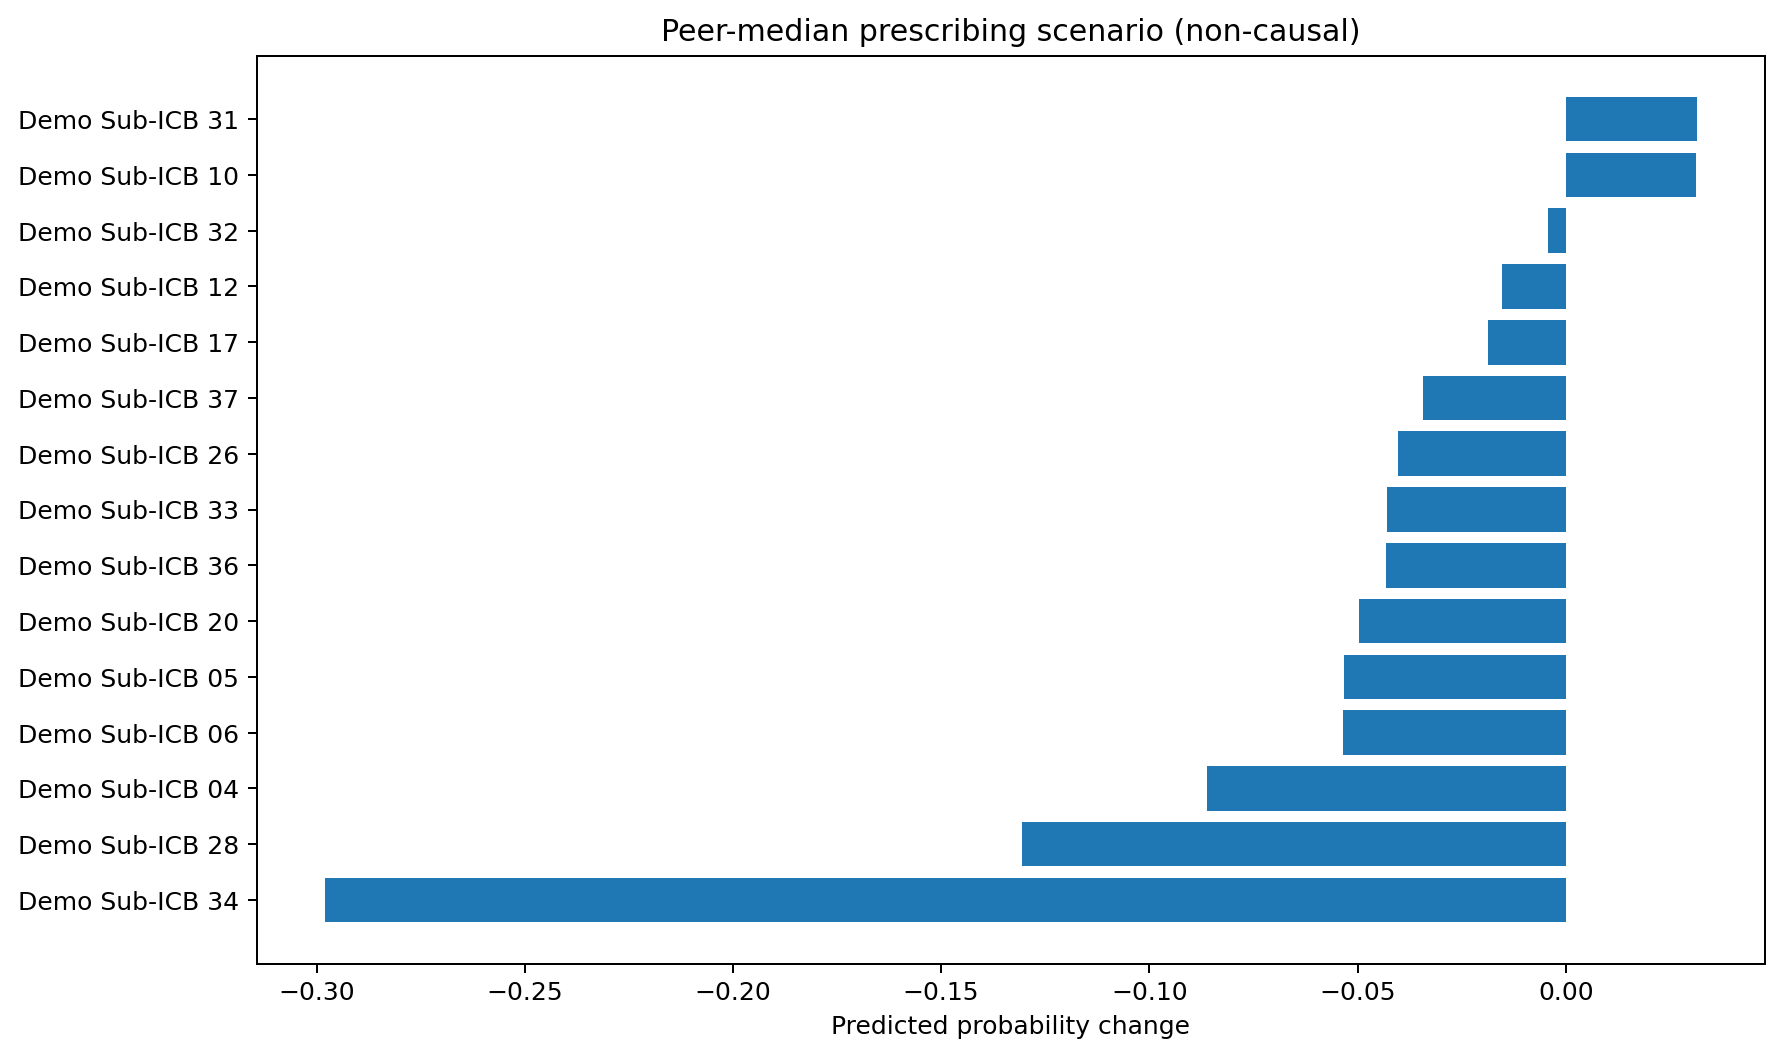

In [ ]:
scenario = run_scenario(cfg)
scenario_path = figure_dir / "scenario_probability_changes.png"
plot_scenario(scenario, scenario_path)

display(
    scenario[[
        "area_name", "broad_spectrum_items_per_1000", "peer_target_prescribing",
        "observed_probability", "scenario_probability", "predicted_probability_change"
    ]].head(12).round(3)
)
display(Image(filename=str(scenario_path)))

In [ ]:
summary = json.loads((table_dir / "analysis_summary.json").read_text())
scenario_active = int((scenario["scenario_prescribing"] < scenario["broad_spectrum_items_per_1000"] - 1e-12).sum())

final_summary = pd.DataFrame({
    "Result": [
        "Area-quarter observations",
        "Areas",
        "Trajectory classes",
        "DTW silhouette",
        "DTW adjusted Rand index",
        "Final holdout balanced accuracy",
        "Final holdout ROC-AUC",
        "Areas with prescribing lowered in scenario",
    ],
    "Value": [
        summary["panel_rows"],
        summary["areas"],
        len(summary["trajectory_class_counts"]),
        round(cluster_metrics["silhouette_precomputed"], 3),
        round(cluster_metrics.get("adjusted_rand_vs_synthetic_truth", np.nan), 3),
        round(metrics["balanced_accuracy"], 3),
        round(metrics["roc_auc"], 3),
        scenario_active,
    ],
})
display(final_summary)

,Result,Value
0,Area-quarter observations,840.000
1,Areas,40.000
2,Trajectory classes,4.000
3,DTW silhouette,0.490
4,DTW adjusted Rand index,1.000
5,Final holdout balanced accuracy,0.722
6,Final holdout ROC-AUC,0.710
7,Areas with prescribing lowered in scenario,19.000
